In [2]:
!pip install timm


     ---------------------------------------- 0.0/63.1 kB ? eta -:--:--
     ------------------- -------------------- 30.7/63.1 kB 1.4 MB/s eta 0:00:01
     ------------------- -------------------- 30.7/63.1 kB 1.4 MB/s eta 0:00:01
     -------------------------------------- 63.1/63.1 kB 485.1 kB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   - -------------------------------------- 0.1/2.5 MB 5.5 MB/s eta 0:00:01
   - -------------------------------------- 0.1/2.5 MB 5.5 MB/s eta 0:00:01
   - -------------------------------------- 0.1/2.5 MB 1.1 MB/s eta 0:00:03
   --- ------------------------------------ 0.2/2.5 MB 1.5 MB/s eta 0:00:02
   --- ------------------------------------ 0.2/2.5 MB 1.4 MB/s eta 0:00:02
   ---- ----------------------------------- 0.3/2.5 MB 983.0 kB/s eta 0:00:03
   ------ --------------------------------- 0.4/2.5 MB 1.2 MB/s eta 0:00:02
   -------- ------------------------------- 0.5/2.5 MB 1.5 MB/s eta 0:00:02
   ------


[notice] A new release of pip is available: 24.0 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import timm
print(timm.list_models('vit*'))


['vit_7b_patch16_dinov3', 'vit_base_mci_224', 'vit_base_patch8_224', 'vit_base_patch14_dinov2', 'vit_base_patch14_reg4_dinov2', 'vit_base_patch16_18x2_224', 'vit_base_patch16_224', 'vit_base_patch16_224_miil', 'vit_base_patch16_384', 'vit_base_patch16_clip_224', 'vit_base_patch16_clip_384', 'vit_base_patch16_clip_quickgelu_224', 'vit_base_patch16_dinov3', 'vit_base_patch16_dinov3_qkvb', 'vit_base_patch16_gap_224', 'vit_base_patch16_plus_240', 'vit_base_patch16_plus_clip_240', 'vit_base_patch16_reg4_gap_256', 'vit_base_patch16_rope_224', 'vit_base_patch16_rope_ape_224', 'vit_base_patch16_rope_mixed_224', 'vit_base_patch16_rope_mixed_ape_224', 'vit_base_patch16_rope_reg1_gap_256', 'vit_base_patch16_rpn_224', 'vit_base_patch16_siglip_224', 'vit_base_patch16_siglip_256', 'vit_base_patch16_siglip_384', 'vit_base_patch16_siglip_512', 'vit_base_patch16_siglip_gap_224', 'vit_base_patch16_siglip_gap_256', 'vit_base_patch16_siglip_gap_384', 'vit_base_patch16_siglip_gap_512', 'vit_base_patch16_xp

In [4]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import matplotlib.pyplot as plt
from tqdm import tqdm


In [5]:
IMG_PATH = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\images"
LBL_PATH = r"C:\Users\PRAVEEN S\Desktop\BrainTumor-Cloud-AI\data\raw\processed\labels"

class BrainMRIDataset(Dataset):
    def __init__(self, image_files, img_path, lbl_path):
        self.image_files = image_files
        self.img_path = img_path
        self.lbl_path = lbl_path

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]

        img = cv2.imread(os.path.join(self.img_path, img_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (224, 224))
        img = img / 255.0
        img = torch.tensor(img, dtype=torch.float32).permute(2,0,1)

        label_file = img_name.replace(".png", ".txt")
        with open(os.path.join(self.lbl_path, label_file)) as f:
            label = int(f.read().strip())

        return img, label


In [6]:
all_images = sorted(os.listdir(IMG_PATH))

train_imgs, val_imgs = train_test_split(
    all_images, test_size=0.2, random_state=42, stratify=[
        int(open(os.path.join(LBL_PATH, f.replace(".png",".txt"))).read())
        for f in all_images
    ]
)

train_ds = BrainMRIDataset(train_imgs, IMG_PATH, LBL_PATH)
val_ds   = BrainMRIDataset(val_imgs, IMG_PATH, LBL_PATH)

train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=8, shuffle=False)


In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "vit_small_patch16_224",
    pretrained=True,
    num_classes=1
)

model.to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

c:\Users\PRAVEEN S\AppData\Local\Programs\Python\Python39\lib\site-packages\huggingface_hub\file_download.py:157: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\PRAVEEN S\.cache\huggingface\hub\models--timm--vit_small_patch16_224.augreg_in21k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to see activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [8]:
def train_epoch(loader):
    model.train()
    total_loss = 0
    for imgs, labels in tqdm(loader):
        imgs = imgs.to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()
        outputs = model(imgs).squeeze()
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)


In [9]:
def eval_epoch(loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            outputs = torch.sigmoid(model(imgs)).cpu().numpy()
            preds.extend((outputs > 0.5).astype(int))
            trues.extend(labels.numpy())
    return preds, trues


In [10]:
EPOCHS = 5

for epoch in range(EPOCHS):
    loss = train_epoch(train_loader)
    preds, trues = eval_epoch(val_loader)
    print(f"Epoch {epoch+1} | Loss: {loss:.4f}")


100%|██████████| 694/694 [21:56<00:00,  1.90s/it]


Epoch 1 | Loss: 0.3153


100%|██████████| 694/694 [29:41<00:00,  2.57s/it]


Epoch 2 | Loss: 0.1604


100%|██████████| 694/694 [26:13<00:00,  2.27s/it]


Epoch 3 | Loss: 0.0905


100%|██████████| 694/694 [24:03<00:00,  2.08s/it]


Epoch 4 | Loss: 0.0676


100%|██████████| 694/694 [27:51<00:00,  2.41s/it]


Epoch 5 | Loss: 0.0570


              precision    recall  f1-score   support

           0       0.96      0.96      0.96       761
           1       0.96      0.95      0.95       627

    accuracy                           0.96      1388
   macro avg       0.96      0.96      0.96      1388
weighted avg       0.96      0.96      0.96      1388



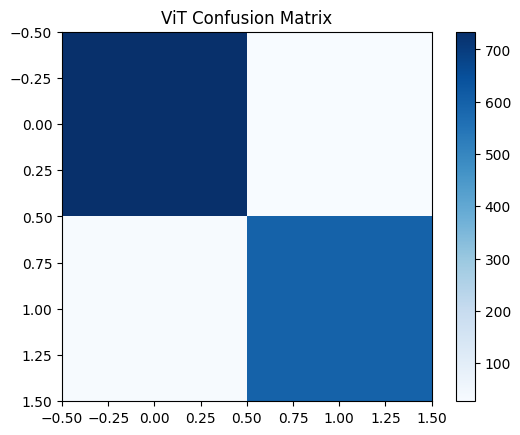

In [11]:
print(classification_report(trues, preds))

cm = confusion_matrix(trues, preds)
plt.imshow(cm, cmap="Blues")
plt.title("ViT Confusion Matrix")
plt.colorbar()
plt.show()
